<a href="https://colab.research.google.com/github/aronyo24/aronyo24-NISAR_Bangladesh_Flood_Monitor/blob/main/Copy_of_NISAR_Bangladesh_Flood_Monitor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NISAR Bangladesh Flood Monitor — all 64 districts
This notebook finds all NASA-ISRO NISAR radar images over Bangladesh, detects flooding in each image, and computes statistics for all 64 districts. All results are saved directly to Google Drive, ensuring progress is preserved if the Colab session disconnects. When run again, it continues from where it stopped and only processes new images.

### Two stages
| Stage | Action | Execution Time |
|---|---|---|
| **Stage A** | Download each image → shrink and save to Google Drive → delete large temporary files | Heavy processing, typically completed over multiple runs |
| **Stage B** | Detect floods from shrunk images → compute 64-district statistics → generate website files | Fast |


## 1. Install tools

In [ ]:
!pip install -q asf_search h5py pyproj scikit-image rasterio geopandas shapely
print("✅ Tools installed")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.0/133.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 7.4 MB/s eta 0:00:00
✅ Tools installed


## 2. Connect Google Drive
All results will be saved in `MyDrive/nisar_bangladesh`.

In [ ]:
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/nisar_bangladesh"
    TMP = "/content/tmp_h5"                      # big files: local disk, deleted after use
except ImportError:
    BASE = os.path.abspath("nisar_bangladesh")
    TMP = os.path.join(BASE, "tmp_h5")

SMALL = os.path.join(BASE, "scenes_small")       # small processed copies (kept)
WEB = os.path.join(BASE, "web_data")             # files for the Django website
OVERLAYS = os.path.join(WEB, "overlays")
for d in (TMP, SMALL, WEB, OVERLAYS):
    os.makedirs(d, exist_ok=True)
print("✅ Saving everything in:", BASE)

Mounted at /content/drive
✅ Saving everything in: /content/drive/MyDrive/nisar_bangladesh


## 3. NASA Earthdata Login

In [ ]:
import asf_search as asf
from getpass import getpass

username = input("Earthdata username: ")
password = getpass("Earthdata password: ")
try:
    session = asf.ASFSession().auth_with_creds(username, password)
    print(" Logged in ")
except Exception as e:
    print(" Login failed ", e)
    print("Check: correct username/password? Email verified at urs.earthdata.nasa.gov?")

Earthdata username: aronyo
Earthdata password: ··········
✅ Logged in / লগইন সফল


## 4. Settings
Usually, no changes are needed here.

In [ ]:
from datetime import datetime, timezone

START = "2026-06-17"                                   # NISAR provisional data starts here
END = datetime.now(timezone.utc).date().isoformat()    # up to today
FACTOR = 8                  # average 8x8 pixels -> 80-160 m pixels: enough for districts, much faster
MAX_SCENES_PER_RUN = 30     # Stage A processes this many new images per run
PERSISTENCE = 0.9           # water in >=90% of images = normal water (river, beel)
MIN_SCENES_FOR_PERSISTENCE = 4
CYCLE_DAYS = 12             # NISAR repeat cycle; results are grouped per 12 days
MIN_OBSERVED_KM2 = 1.0      # ignore tiny slivers of a district at an image edge
MIN_SEPARATION_DB = 6.0     # water must be at least this much darker than land, else borrow a cutoff
FALLBACK_CUTOFF_DB = -18.0  # used only if NO frame shows clear water (check against real data)
print(f"Period: {START} -> {END}")

Period: 2026-06-17 -> 2026-09-29


## 5. District boundaries
Source: [geoBoundaries](https://www.geoboundaries.org) Bangladesh ADM2 (open license, CC BY 4.0)

In [ ]:
import requests
import geopandas as gpd
from shapely.geometry.polygon import orient

RAW_FILE = os.path.join(WEB, "districts_raw.geojson")
CLEAN_FILE = os.path.join(WEB, "districts.geojson")
URL = ("https://media.githubusercontent.com/media/wmgeolab/geoBoundaries/main/"
       "releaseData/gbOpen/BGD/ADM2/geoBoundaries-BGD-ADM2_simplified.geojson")

if not os.path.exists(RAW_FILE):
    r = requests.get(URL, timeout=180)
    r.raise_for_status()
    with open(RAW_FILE, "wb") as fh:
        fh.write(r.content)

districts = gpd.read_file(RAW_FILE).to_crs(4326)
districts = districts.rename(columns={"shapeName": "district"})[["district", "geometry"]]
districts = districts.sort_values("district").reset_index(drop=True)
districts["district_id"] = range(1, len(districts) + 1)
districts["area_km2"] = (districts.to_crs(6933).area / 1e6).round(1)
districts.to_file(CLEAN_FILE, driver="GeoJSON")

bd_shape = districts.union_all() if hasattr(districts, "union_all") else districts.unary_union
search_wkt = orient(bd_shape.convex_hull, 1.0).wkt
print(f"✅ {len(districts)} districts loaded, total {districts.area_km2.sum():,.0f} km²")

✅ 64 districts loaded, total 139,830 km²


## 6. Find all NISAR images over Bangladesh
Images of the same geographic area and orbit path are grouped as a single "frame" (e.g., `T045A_F071`).

In [ ]:
from shapely.geometry import shape
import pandas as pd

def parse_name(fname):
    # NISAR_L2_PT_GCOV_CYL_REL_P_FRM_MODE_POLE_S_Start_End_CRID_A_C_LOC_CTR.h5
    p = os.path.basename(fname).rsplit(".", 1)[0].split("_")
    return {"pt": p[2], "track": p[5], "dir": p[6], "frame": p[7],
            "start": p[11], "crid": p[13]}

def small_path(name):
    return os.path.join(SMALL, os.path.basename(name).rsplit(".", 1)[0] + ".npz")

try:
    results = asf.search(dataset="NISAR", processingLevel="GCOV",
                         intersectsWith=search_wkt, start=START, end=END)
except Exception:
    results = []
if len(results) == 0:
    results = asf.search(dataset="NISAR", intersectsWith=search_wkt, start=START, end=END)

best = {}
for r in results:
    url = r.properties.get("url") or ""
    name = os.path.basename(url)
    if "_GCOV_" not in name or not name.lower().endswith(".h5"):
        continue
    try:
        if not shape(r.geometry).intersects(bd_shape):
            continue                          # image does not touch Bangladesh
    except Exception:
        pass
    try:
        info = parse_name(name)
    except IndexError:
        continue
    ident = (info["track"], info["dir"], info["frame"], info["start"])
    rank = (info["pt"] == "PR", info["crid"])   # prefer production, newest version
    if ident not in best or rank > best[ident]["rank"]:
        best[ident] = {"name": name, "url": url, "result": r, "rank": rank,
                       "key": f"T{info['track']}{info['dir']}_F{info['frame']}",
                       "date": f"{info['start'][:4]}-{info['start'][4:6]}-{info['start'][6:8]}"}

catalog = sorted(best.values(), key=lambda c: (c["key"], c["date"]))
for c in catalog:
    c["done"] = os.path.exists(small_path(c["name"]))

if not catalog:
    print("❌ No GCOV images found over Bangladesh. First items returned (send to Claude):")
    for r in list(results)[:15]:
        print("  ", r.properties.get("fileID"), r.properties.get("url"))
else:
    cat_df = pd.DataFrame([{k: c[k] for k in ("key", "date", "name", "done")} for c in catalog])
    cat_df.to_csv(os.path.join(BASE, "catalog.csv"), index=False)
    per_frame = cat_df.groupby("key").agg(images=("name", "size"), first=("date", "min"),
                                          last=("date", "max"), done=("done", "sum"))
    print(f"✅ {len(catalog)} images in {len(per_frame)} frames; "
          f"{int(cat_df.done.sum())} already processed, {int((~cat_df.done).sum())} to go")
    display(per_frame)

["'type': 'GEOMETRY_SIMPLIFICATION': 'report': 'Shape Simplified: shape of 23 simplified to 20 with proximity threshold of 0.0004'"]


✅ 176 images in 23 frames; 0 already processed, 176 to go


,images,first,last,done
key,,,,
T019D_F075,7,2026-06-27,2026-09-19,0
T019D_F076,10,2026-06-27,2026-09-19,0
T019D_F077,10,2026-06-27,2026-09-19,0
T019D_F078,3,2026-08-26,2026-09-19,0
T069A_F012,8,2026-06-18,2026-09-22,0
T069A_F013,8,2026-06-18,2026-09-22,0
T069A_F014,8,2026-06-18,2026-09-22,0
T069A_F015,8,2026-06-18,2026-09-22,0
T091D_F076,8,2026-06-20,2026-09-24,0


## 7. Stage A: Download and shrink
For each image: download to local disk → average 8×8 pixels (reduces speckle noise) → convert to dB → save a small compressed file on Google Drive → delete the large H5 file.

⏳ Processing each image can take a couple of minutes. If the run stops or reaches limits, run again to resume without losing completed work.

In [ ]:
import time, warnings
import h5py
import numpy as np

def find(f, name, prefer="frequencyA"):
    hits = []
    def visit(path, obj):
        if isinstance(obj, h5py.Dataset) and path.endswith("/" + name):
            hits.append(path)
    f.visititems(visit)
    if not hits:
        raise KeyError(name)
    hits.sort(key=lambda p: (prefer not in p, "GCOV" not in p, len(p)))
    return f[hits[0]]

def read_multilooked(path, k=FACTOR):
    # Reads the backscatter band in row blocks (low memory) and averages k x k pixels.
    with h5py.File(path, "r") as f:
        x = find(f, "xCoordinates")[:]
        y = find(f, "yCoordinates")[:]
        proj = find(f, "projection")
        epsg = proj.attrs.get("epsg_code")
        if epsg is None:
            epsg = proj[()]
        epsg = int(np.array(epsg).ravel()[0])
        try:
            band = find(f, "HHHH")
        except KeyError:
            band = find(f, "VVVV")
        H, W = band.shape
        h, w = H // k, W // k
        out = np.full((h, w), np.nan, dtype="float32")
        step = k * 64
        for r0 in range(0, h * k, step):
            blk = band[r0:min(r0 + step, h * k), : w * k].astype("float32")
            blk[~(blk > 0)] = np.nan
            nb = blk.shape[0] // k
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", category=RuntimeWarning)
                out[r0 // k: r0 // k + nb] = np.nanmean(blk[: nb * k].reshape(nb, k, w, k), axis=(1, 3))
        layer = band.name.split("/")[-1]
    xs = x[: w * k].reshape(w, k).mean(1)
    ys = y[: h * k].reshape(h, k).mean(1)
    if ys[1] > ys[0]:                       # make north-up
        out, ys = out[::-1], ys[::-1]
    with np.errstate(divide="ignore", invalid="ignore"):
        db = 10 * np.log10(out)
    return db, xs, ys, epsg, layer

def process_scene(c):
    local = os.path.join(TMP, c["name"])
    if not os.path.exists(local):
        c["result"].download(path=TMP, session=session)
    try:
        db, xs, ys, epsg, layer = read_multilooked(local)
        np.savez_compressed(small_path(c["name"]), db=db.astype("float16"), x=xs, y=ys,
                            epsg=epsg, date=c["date"], key=c["key"], name=c["name"], layer=layer)
    finally:
        if os.path.exists(local):
            os.remove(local)                 # free disk space

todo = [c for c in catalog if not os.path.exists(small_path(c["name"]))]
print(f"{len(todo)} images to process; doing up to {MAX_SCENES_PER_RUN} now")
errors = []
for i, c in enumerate(todo[:MAX_SCENES_PER_RUN], 1):
    t0 = time.time()
    try:
        process_scene(c)
        print(f"  ✅ {i:3d}. {c['date']} {c['key']}  ({time.time() - t0:.0f}s)")
    except Exception as e:
        errors.append((c["name"], str(e)))
        print(f"  ❌ {i:3d}. {c['date']} {c['key']}: {e}")

left = sum(not os.path.exists(small_path(c["name"])) for c in catalog)
if errors:
    with open(os.path.join(BASE, "errors.txt"), "a") as fh:
        for n, e in errors:
            fh.write(f"{n}\t{e}\n")
print(f"Done for now. Remaining images: {left}. "
      + ("Run the notebook again to continue." if left else "All images processed! 🎉"))

176 images to process; doing up to 30 now
  ✅   1. 2026-06-27 T019D_F075  (131s)
  ✅   2. 2026-07-09 T019D_F075  (135s)
  ✅   3. 2026-07-21 T019D_F075  (153s)
  ✅   4. 2026-08-14 T019D_F075  (138s)
  ✅   5. 2026-08-26 T019D_F075  (145s)
  ✅   6. 2026-09-07 T019D_F075  (147s)
  ✅   7. 2026-09-19 T019D_F075  (138s)
  ✅   8. 2026-06-27 T019D_F076  (81s)
  ✅   9. 2026-06-27 T019D_F076  (36s)
  ✅  10. 2026-07-09 T019D_F076  (114s)
  ✅  11. 2026-07-09 T019D_F076  (39s)
  ✅  12. 2026-07-21 T019D_F076  (165s)
  ✅  13. 2026-08-14 T019D_F076  (142s)
  ✅  14. 2026-08-26 T019D_F076  (131s)
  ✅  15. 2026-09-07 T019D_F076  (86s)
  ✅  16. 2026-09-07 T019D_F076  (37s)
  ✅  17. 2026-09-19 T019D_F076  (111s)
  ✅  18. 2026-06-27 T019D_F077  (125s)
  ✅  19. 2026-07-09 T019D_F077  (92s)
  ✅  20. 2026-07-09 T019D_F077  (59s)
  ✅  21. 2026-07-21 T019D_F077  (87s)
  ✅  22. 2026-07-21 T019D_F077  (57s)
  ✅  23. 2026-08-14 T019D_F077  (86s)
  ✅  24. 2026-08-14 T019D_F077  (62s)
  ✅  25. 2026-08-26 T019D_F077  (

## 8. Stage B: Find floods and compute district statistics

**Method:**
1. Analyze all images in a frame together to determine the water-land backscatter threshold (dB) using the **Otsu** method. If a frame lacks sufficient contrast (e.g., dry season, no water), it borrows the cutoff from other frames to prevent false positives.
2. Water pixels are identified as those darker than the threshold.
3. **Normal water** = areas where water is present in >=90% of the images (rivers, permanent wetlands). If fewer than 4 images exist, the first image is used as the baseline.
4. **Flood** = detected water that is not part of the normal water mask.
5. Compute the total observed area (km²) and flooded area (km²) for each district.
6. Group statistics by 12-day periods (NISAR repeat cycle) to report district flood percentages and national aggregates.

In [ ]:
import glob
import pandas as pd
from collections import defaultdict
from skimage.filters import threshold_otsu
from rasterio import features
from rasterio.transform import from_origin
from rasterio.warp import calculate_default_transform, reproject, Resampling, transform_bounds
from rasterio.crs import CRS
import matplotlib.pyplot as plt

def load_small(path):
    z = np.load(path, allow_pickle=False)
    return {"db": z["db"].astype("float32"), "x": z["x"], "y": z["y"], "epsg": int(z["epsg"]),
            "date": str(z["date"]), "key": str(z["key"]), "name": str(z["name"])}

def paste(ref_shape, src, row_off, col_off):
    # place src into an array shaped like the reference grid, shifted by (row_off, col_off)
    out = np.full(ref_shape, np.nan, dtype="float32")
    r0, c0 = max(row_off, 0), max(col_off, 0)
    r1 = min(ref_shape[0], row_off + src.shape[0])
    c1 = min(ref_shape[1], col_off + src.shape[1])
    if r1 > r0 and c1 > c0:
        out[r0:r1, c0:c1] = src[r0 - row_off: r1 - row_off, c0 - col_off: c1 - col_off]
    return out

def colorize(classes):
    rgba = np.zeros(classes.shape + (4,), dtype="uint8")
    rgba[classes == 2] = (37, 99, 235, 170)      # blue  = normal water
    rgba[classes == 3] = (220, 38, 38, 210)      # red   = flood
    return rgba

frames = defaultdict(list)
for p in sorted(glob.glob(os.path.join(SMALL, "*.npz"))):
    s = load_small(p)
    frames[s["key"]].append(s)

obs_rows, overlay_rows, frame_rows = [], [], []
rng = np.random.default_rng(0)

def build_stack(scenes):
    scenes = sorted(scenes, key=lambda s: s["date"])
    ref = scenes[0]
    epsg, x0, y0 = ref["epsg"], ref["x"][0], ref["y"][0]
    dx, dy = ref["x"][1] - ref["x"][0], ref["y"][1] - ref["y"][0]      # dy < 0 (north-up)
    shp = ref["db"].shape
    scenes = [s for s in scenes if s["epsg"] == epsg]
    stack = np.stack([paste(shp, s["db"], int(round((s["y"][0] - y0) / dy)),
                            int(round((s["x"][0] - x0) / dx))) for s in scenes])
    return scenes, stack, epsg, x0, y0, dx, dy, shp

def cutoff_check(stack):
    # Otsu cutoff + a contrast check: real water is much darker than land.
    sample = stack[np.isfinite(stack)]
    if sample.size > 3_000_000:
        sample = rng.choice(sample, 3_000_000, replace=False)
    t = float(threshold_otsu(sample))
    lo, hi = sample[sample < t], sample[sample >= t]
    sep = float(hi.mean() - lo.mean()) if lo.size and hi.size else 0.0
    share = float((sample < t).mean())
    ok = sep >= MIN_SEPARATION_DB and share < 0.5
    return t, sep, share, ok

# pass 1: find a trustworthy cutoff for every frame
checks = {key: cutoff_check(build_stack(sc)[1]) for key, sc in frames.items()}
good = [c[0] for c in checks.values() if c[3]]
fallback_cut = float(np.median(good)) if good else FALLBACK_CUTOFF_DB
print(f"Frames with clear water/land contrast: {len(good)}/{len(checks)}; "
      f"fallback cutoff {fallback_cut:.1f} dB")

# pass 2: flood detection and district statistics
for key, scenes in sorted(frames.items()):
    scenes, stack, epsg, x0, y0, dx, dy, shp = build_stack(scenes)
    valid = np.isfinite(stack)
    t, sep, share, ok = checks[key]
    cutoff = t if ok else fallback_cut
    cut_note = "own Otsu cutoff" if ok else f"borrowed cutoff (own contrast only {sep:.1f} dB)"
    water = (stack < cutoff) & valid

    n_valid = valid.sum(0)
    if len(scenes) >= MIN_SCENES_FOR_PERSISTENCE:
        with np.errstate(invalid="ignore", divide="ignore"):
            persistence = np.where(n_valid > 0, water.sum(0) / n_valid, 0)
        normal = (persistence >= PERSISTENCE) & (n_valid >= MIN_SCENES_FOR_PERSISTENCE)
        method = f"water in >= {int(PERSISTENCE * 100)}% of {len(scenes)} images"
    else:
        normal = water[0]
        method = f"first image ({scenes[0]['date']}) as baseline, only {len(scenes)} images"

    transform = from_origin(x0 - dx / 2, y0 - dy / 2, dx, -dy)
    dist_crs = districts.to_crs(epsg)
    dist_ids = features.rasterize(zip(dist_crs.geometry, dist_crs.district_id), out_shape=shp,
                                  transform=transform, fill=0, dtype="int32")
    px_km2 = abs(dx * dy) / 1e6
    nd = len(districts) + 1

    for i, s in enumerate(scenes):
        v, wtr = valid[i], water[i]
        flood = wtr & ~normal & v
        obs = np.bincount(dist_ids[v], minlength=nd) * px_km2
        fld = np.bincount(dist_ids[flood], minlength=nd) * px_km2
        wat = np.bincount(dist_ids[wtr], minlength=nd) * px_km2
        for d in districts.itertuples():
            if obs[d.district_id] >= MIN_OBSERVED_KM2:
                obs_rows.append({"date": s["date"], "frame": key, "district": d.district,
                                 "district_id": d.district_id,
                                 "observed_km2": round(obs[d.district_id], 2),
                                 "water_km2": round(wat[d.district_id], 2),
                                 "flood_km2": round(fld[d.district_id], 2),
                                 "image": s["name"]})

        # map overlay (only inside Bangladesh), reprojected to Web Mercator for Leaflet
        classes = np.zeros(shp, dtype="uint8")
        classes[v] = 1
        classes[v & wtr & normal] = 2
        classes[flood] = 3
        classes[dist_ids == 0] = 0
        left, top = x0 - dx / 2, y0 - dy / 2
        right, bottom = left + dx * shp[1], top + dy * shp[0]
        dst_t, dw, dh = calculate_default_transform(CRS.from_epsg(epsg), CRS.from_epsg(3857),
                                                    shp[1], shp[0], left, bottom, right, top)
        merc = np.zeros((dh, dw), dtype="uint8")
        reproject(classes, merc, src_transform=transform, src_crs=CRS.from_epsg(epsg),
                  dst_transform=dst_t, dst_crs=CRS.from_epsg(3857), resampling=Resampling.nearest)
        png = f"{s['date']}_{key}.png"
        plt.imsave(os.path.join(OVERLAYS, png), colorize(merc))
        west, north = dst_t * (0, 0)
        east, south = dst_t * (dw, dh)
        w4, s4, e4, n4 = transform_bounds(CRS.from_epsg(3857), CRS.from_epsg(4326), west, south, east, north)
        overlay_rows.append({"date": s["date"], "frame": key, "file": f"overlays/{png}",
                             "bounds": [[round(s4, 5), round(w4, 5)], [round(n4, 5), round(e4, 5)]]})

    water_share = float(water[valid].mean()) if valid.any() else 0.0
    frame_rows.append({"frame": key, "images": len(scenes), "epsg": epsg,
                       "water_cutoff_db": round(cutoff, 2), "cutoff_source": cut_note,
                       "contrast_db": round(sep, 1), "normal_water_method": method,
                       "first": scenes[0]["date"], "last": scenes[-1]["date"],
                       "water_share": round(water_share, 3),
                       "check": "⚠️ check: very high water share" if water_share > 0.5 else "ok"})
    print(f"  ✅ {key}: {len(scenes)} images, cutoff {cutoff:.1f} dB ({cut_note}), "
          f"normal water = {method}")

obs_df = pd.DataFrame(obs_rows)
frames_df = pd.DataFrame(frame_rows)
print(f"✅ {len(frames_df)} frames analysed, {len(obs_df)} district observations")

Frames with clear water/land contrast: 4/4; fallback cutoff -49.7 dB
  ✅ T019D_F075: 7 images, cutoff -67.7 dB (own Otsu cutoff), normal water = water in >= 90% of 7 images
  ✅ T019D_F076: 10 images, cutoff -69.1 dB (own Otsu cutoff), normal water = water in >= 90% of 10 images
  ✅ T019D_F077: 10 images, cutoff -12.4 dB (own Otsu cutoff), normal water = water in >= 90% of 10 images
  ✅ T019D_F078: 3 images, cutoff -31.6 dB (own Otsu cutoff), normal water = first image (2026-08-26) as baseline, only 3 images
✅ 4 frames analysed, 487 district observations


## 9. District and national results per 12-day cycle

In [ ]:
import json
start_day = pd.Timestamp(START)
obs_df["date"] = pd.to_datetime(obs_df["date"])
obs_df["cycle"] = ((obs_df["date"] - start_day).dt.days // CYCLE_DAYS).astype(int)
obs_df["cycle_start"] = start_day + pd.to_timedelta(obs_df["cycle"] * CYCLE_DAYS, unit="D")

cyc = (obs_df.groupby(["cycle_start", "district_id", "district"], as_index=False)
             .agg(observed_km2=("observed_km2", "sum"), flood_km2_seen=("flood_km2", "sum"),
                  last_image=("date", "max"), images=("image", "nunique")))
cyc = cyc.merge(districts[["district_id", "area_km2"]], on="district_id")
cyc["coverage_pct"] = (100 * cyc.observed_km2 / cyc.area_km2).clip(upper=100).round(1)
cyc["flood_pct"] = (100 * cyc.flood_km2_seen / cyc.observed_km2).round(2)
cyc["flood_km2_est"] = (cyc.flood_pct / 100 * cyc.area_km2).round(1)
cyc = cyc.sort_values(["cycle_start", "district"])

nat = (cyc.groupby("cycle_start", as_index=False)
          .agg(flood_km2_est=("flood_km2_est", "sum"), districts_seen=("district_id", "nunique"),
               area_seen_km2=("area_km2", "sum")))
nat["flood_km2_est"] = nat.flood_km2_est.round(0)

# ---- save everything the website needs
for df in (obs_df, cyc, nat):
    for col in ("date", "cycle_start", "last_image"):
        if col in df:
            df[col] = pd.to_datetime(df[col]).dt.strftime("%Y-%m-%d")
obs_df.drop(columns=["cycle"]).to_csv(os.path.join(WEB, "district_observations.csv"), index=False)
cyc.to_csv(os.path.join(WEB, "district_cycles.csv"), index=False)
nat.to_csv(os.path.join(WEB, "national_cycles.csv"), index=False)
frames_df.to_csv(os.path.join(WEB, "frames.csv"), index=False)
cyc.to_json(os.path.join(WEB, "district_cycles.json"), orient="records", indent=1)
nat.to_json(os.path.join(WEB, "national_cycles.json"), orient="records", indent=1)
with open(os.path.join(WEB, "overlays.json"), "w") as fh:
    json.dump(sorted(overlay_rows, key=lambda o: (o["date"], o["frame"])), fh, indent=1)
with open(os.path.join(WEB, "meta.json"), "w") as fh:
    json.dump({"generated_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
               "period": [START, END], "cycle_days": CYCLE_DAYS, "pixel_average": FACTOR,
               "persistence": PERSISTENCE,
               "data": "NASA-ISRO NISAR L2 GCOV, PROVISIONAL, via ASF DAAC",
               "boundaries": "geoBoundaries BGD ADM2 (CC BY 4.0)"}, fh, indent=1)
print("✅ Website files saved in", WEB)
display(nat)

✅ Website files saved in /content/drive/MyDrive/nisar_bangladesh/web_data


,cycle_start,flood_km2_est,districts_seen,area_seen_km2
0,2026-06-17,3668.0,38,79635.5
1,2026-06-29,974.0,51,100853.3
2,2026-07-11,7261.0,51,102862.3
3,2026-08-04,8337.0,51,102862.3
4,2026-08-16,4302.0,38,79635.5
5,2026-08-28,4254.0,38,79635.5
6,2026-09-09,3892.0,38,79635.5


## 10. Quick look
National flood area timeline and the district flood percentage map for the worst-affected cycle.

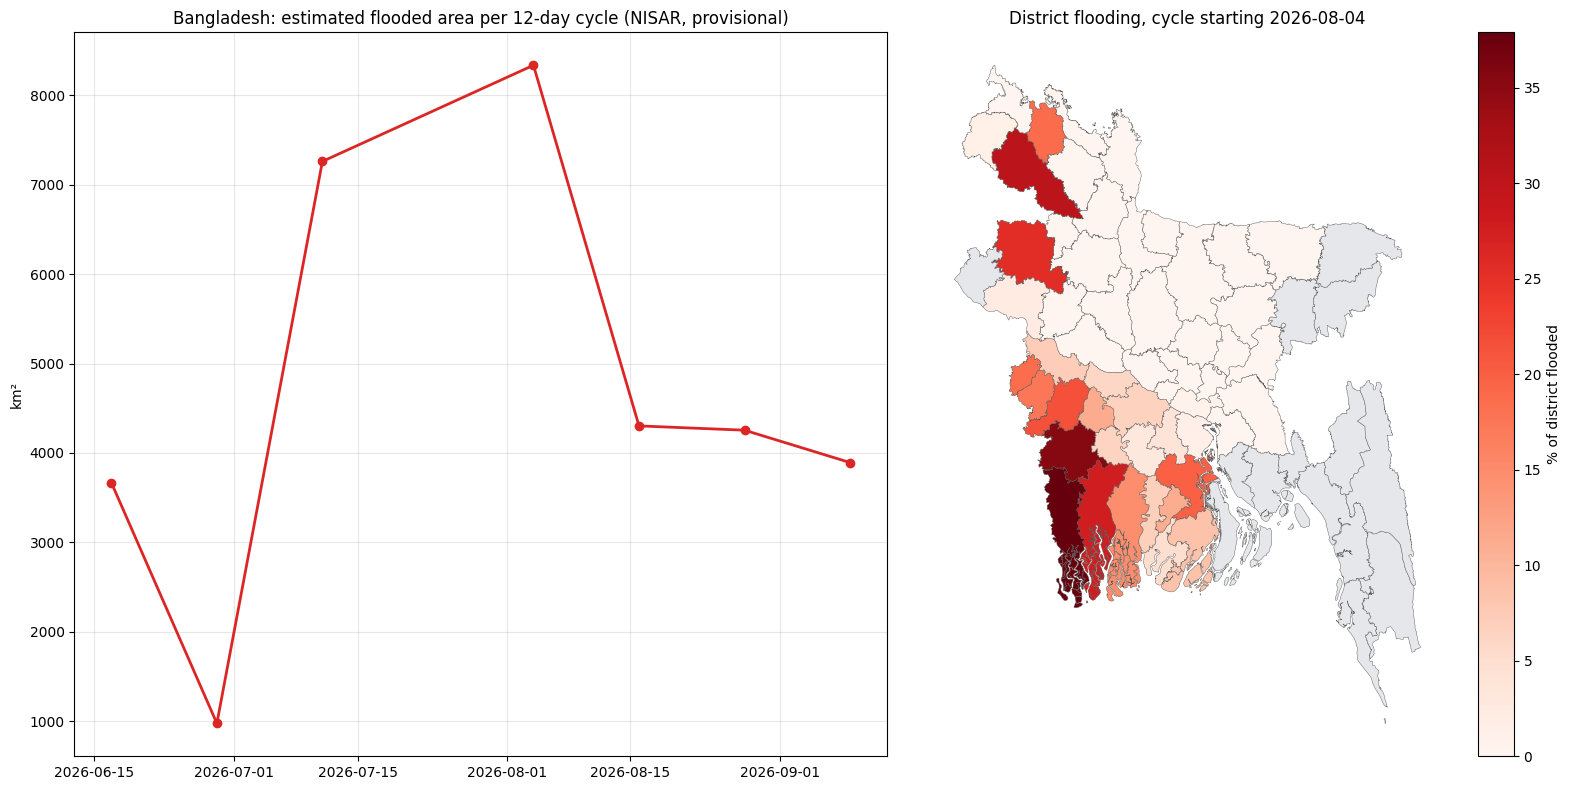

Top 10 districts, cycle starting 2026-08-04:


,district,flood_pct,coverage_pct
0,Satkhira,37.91,75.7
1,Jessore,35.54,100.0
2,Dinajpur,30.44,57.4
3,Khulna,27.72,75.6
4,Naogaon,25.49,80.2
5,Jhenaidah,21.49,100.0
6,Barisal,19.91,42.3
7,Nilphamari,18.77,100.0
8,Meherpur,18.52,100.0
9,Chuadanga,17.37,100.0


In [ ]:
worst = nat.loc[nat.flood_km2_est.idxmax(), "cycle_start"]
snap = districts.merge(cyc[cyc.cycle_start == worst][["district_id", "flood_pct", "coverage_pct"]],
                       on="district_id", how="left")

fig, ax = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1.2, 1]})
ax[0].plot(pd.to_datetime(nat.cycle_start), nat.flood_km2_est, marker="o", color="#dc2626", lw=2)
ax[0].set_title("Bangladesh: estimated flooded area per 12-day cycle (NISAR, provisional)")
ax[0].set_ylabel("km²")
ax[0].grid(alpha=0.3)
snap.plot(column="flood_pct", ax=ax[1], cmap="Reds", legend=True, edgecolor="#555", linewidth=0.3,
          missing_kwds={"color": "#e5e7eb", "label": "not observed"},
          legend_kwds={"label": "% of district flooded"})
ax[1].set_title(f"District flooding, cycle starting {worst}")
ax[1].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(WEB, "preview.png"), dpi=110)
plt.show()

top = snap.dropna(subset=["flood_pct"]).sort_values("flood_pct", ascending=False).head(10)
print(f"Top 10 districts, cycle starting {worst}:")
display(top[["district", "flood_pct", "coverage_pct"]].reset_index(drop=True))

## 11. Download the website files

In [ ]:
import shutil
zip_path = shutil.make_archive("/content/web_data" if os.path.exists("/content") else os.path.join(BASE, "web_data"),
                               "zip", WEB)
print("✅", zip_path, f"{os.path.getsize(zip_path) / 1e6:.1f} MB")
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass

✅ /content/web_data.zip 2.1 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>